# PhytoDA — depth-guided seed phenotyping on one demo image (minimal reproduction)

**Paper:** Yan Ma, Pu Jing, Jinfeng Zhao, Xuehui Huang, Xiaoyi Zhou, *"PhytoDA: a depth-guided plant phenotyping and annotation platform for complex crop-image analysis"*, Crop Design (2026), DOI: [10.1016/j.cropd.2026.100168](https://doi.org/10.1016/j.cropd.2026.100168)

**Author code:** https://github.com/Jeepu/PhytoDA (MIT license), pinned commit `5137be999d2a95f73caf0835e2fd6fd9439b3678`

## Purpose and exact scope

PhytoDA is a desktop GUI platform whose automatic engine (Layer 1) processes an RGB image sequentially with
1. **Depth Anything V2 (ViT-L)** monocular depth estimation,
2. **depth-guided foreground gating** (min-max normalization to 0–255, per-image Otsu threshold, mask refinement),
3. **SAM (Segment Anything)** instance segmentation on the gated RGB,
4. task-specific trait extraction.

This notebook reproduces a **partial, single-image demonstration** of that engine headlessly (no GUI):
- it first runs the **authors' own unittest suite** (`tests/test_depth_gated_pipeline.py`), which validates the depth-gated SAM input preparation and strategy routing for all seven task strategies using synthetic inputs and mocked models (no checkpoints needed);
- then it runs the **real pretrained pipeline** on one author-provided demo image (`dataset/Seed/seed_1.jpg`) with the **SeedStrategy**: SAM ViT-B masks + distance-transform watershed separation of touching seeds, producing the six engine stage views, an annotated overlay image, and a seed measurement table (count, length, width, L/W ratio, circularity, area, color) exported to CSV.

**Out of scope:** the GUI itself, the manual annotation workbench, the natural-language Copilot layer, batch processing, and the paper's dataset-level benchmarks (OpenPheno comparison, CVPPP ablation). Trait units are original-image **pixels** (no physical calibration exists in this code path); a single example does not verify the paper's dataset-level MAPE claims.

**実行内容(日本語)**: このノートブックは、著者公開コード(固定コミット)を用いて (1) 著者自身の unittest スイート(モックモデル・合成画像で 7 戦略のdepthゲート処理を検証)と、(2) 著者提供デモ画像 1 枚(`dataset/Seed/seed_1.jpg`)での実推論(Depth Anything V2 ViT-L + SAM ViT-B + watershed による種子計測)を実行します。GUI・Copilot・データセット規模の評価は対象外です。

In [ ]:
import sys, platform, time
import numpy, cv2, scipy, torch, torchvision

print("Python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| torchvision:", torchvision.__version__)
print("opencv      :", cv2.__version__, "| numpy:", numpy.__version__, "| scipy:", scipy.__version__)
cuda = torch.cuda.is_available()
print("CUDA available:", cuda)
if cuda:
    p = torch.cuda.get_device_properties(0)
    print(f"GPU         : {p.name} ({p.total_memory/1024**3:.1f} GB)")
DEVICE = "cuda" if cuda else "cpu"
print("Device      :", DEVICE, "(the author's ModelLoader picks the device the same way)")

Python      : 3.13.16
torch       : 2.14.1+cu130 | torchvision: 0.29.1+cu130
opencv      : 4.14.0 | numpy: 2.4.6 | scipy: 1.16.3
CUDA available: True
GPU         : Tesla T4 (14.6 GB)
Device      : cuda (the author's ModelLoader picks the device the same way)


## Runtime selection

**Recommended: `Runtime` → `Change runtime type` → `T4 GPU`.** The paper reports ~14–15 s/image for the full pipeline on an RTX 4060 laptop GPU and 132–145 s/image on CPU (its Table 3); a T4 should be in the GPU range and any modern CPU also finishes the single demo image within minutes. The notebook runs identically on both (the author code auto-detects CUDA) — only the speed differs.

**Run all:** `Runtime` → `Run all`. Expected total: roughly 5–10 min on T4 (downloads ≈ 1.7 GB of model weights + PySide6), longer on CPU (inference is the slow part).

**実行環境(日本語)**: 推奨は T4 GPU です。CPU でも同じコードが動作しますが、推論が数分かかります。`Run all` で上から順に実行してください。重み約 1.7 GB のダウンロードが必要です。

## 1. Dependencies

The pinned author code bundles its own copies of `segment_anything/` and `depth_anything_v2/`, so no pip model packages are needed. Its import graph requires: `torch`, `torchvision`, `opencv-python`, `numpy`, `scipy` (all preinstalled in Colab) and **`PySide6.QtCore`** — the author's plugin base class uses Qt `QObject`/`Signal` for progress/result signaling, and the signals work headlessly (no QApplication, no display) exactly as in the authors' own unittest. We install the lighter `PySide6-Essentials` wheel, which provides `PySide6.QtCore`.

**日本語**: 著者コードは `segment_anything` と `depth_anything_v2` を同梱しています。不足しているのは Qt シグナル用の `PySide6` のみ(GUI なしのヘッドレス利用)なので、軽量な `PySide6-Essentials` をインストールします。

In [ ]:
import importlib.util, subprocess

if importlib.util.find_spec("PySide6") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "PySide6-Essentials"], check=True)
else:
    print("PySide6 already present")
import PySide6
from PySide6.QtCore import QObject, Signal  # noqa: F401  (headless signal smoke test)
print("PySide6", PySide6.__version__, "- QtCore signals importable without a display")

PySide6 6.12.0 - QtCore signals importable without a display


## 2. Pinned author code (partial clone inside Colab)

We fetch exactly the directories this demo needs from the pinned commit — `core/`, `plugins/`, `segment_anything/`, `depth_anything_v2/`, `tests/` and the demo folder `dataset/Seed/` — using a blob-filtered partial clone with sparse checkout, then assert the checked-out commit equals the pin. Nothing outside these directories is downloaded. (`requirement.txt`/`categories_config.json` are not part of the sparse set; their contents are documented in the README.)

**日本語**: 著者リポジトリを固定コミット `5137be9` で部分クローン(sparse checkout)し、必要なディレクトリだけを取得します。コミット一致を検証します。

In [ ]:
import os, subprocess

REPO_URL = "https://github.com/Jeepu/PhytoDA"
PINNED_COMMIT = "5137be999d2a95f73caf0835e2fd6fd9439b3678"
REPO_DIR = "/content/PhytoDA"

def git(args, cwd=None):
    r = subprocess.run(["git"] + args, cwd=cwd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed:\n{r.stderr}")

if not os.path.isdir(REPO_DIR):
    git(["clone", "--filter=blob:none", "--no-checkout", REPO_URL, REPO_DIR])
    git(["sparse-checkout", "init", "--cone"], cwd=REPO_DIR)
    git(["sparse-checkout", "set", "core", "plugins", "segment_anything",
         "depth_anything_v2", "tests", "dataset/Seed"], cwd=REPO_DIR)
    git(["fetch", "--depth", "1", "origin", PINNED_COMMIT], cwd=REPO_DIR)
    git(["checkout", "--detach", "FETCH_HEAD"], cwd=REPO_DIR)

head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=REPO_DIR,
                      capture_output=True, text=True).stdout.strip()
assert head == PINNED_COMMIT, f"checkout {head} != pinned {PINNED_COMMIT}"
print("Pinned checkout verified:", head)
for d in ["core", "plugins", "segment_anything", "depth_anything_v2", "tests", "dataset/Seed"]:
    n = sum(len(f) for _, _, f in os.walk(os.path.join(REPO_DIR, d)))
    print(f"  {d:20s}: {n} files")

Pinned checkout verified: 5137be999d2a95f73caf0835e2fd6fd9439b3678
  core                : 10 files
  plugins             : 9 files
  segment_anything    : 15 files
  depth_anything_v2   : 12 files
  tests               : 1 files
  dataset/Seed        : 11 files


## 3. Model weights (downloaded into Colab only)

The engine's `ModelLoader` (pinned `core/model_loader.py`) loads two checkpoints from `<repo>/checkpoints/`:
- **SAM ViT-B** `sam_vit_b_01ec64.pth` (~358 MB) — official Meta release file named in the repo README §4.1;
- **Depth Anything V2 ViT-L** `depth_anything_v2_vitl.pth` (~1.34 GB) — official Hugging Face release named in README §4.2.

We validate each download by size range and ZIP signature (PyTorch `.pth` archives start with `PK`) before use.

**日本語**: 著者 README が指定する公式配布元から SAM ViT-B(約358 MB)と Depth Anything V2 ViT-L(約1.34 GB)を Colab 内にのみダウンロードし、サイズとファイル署名を検証します。

In [ ]:
import urllib.request

CKPT_DIR = os.path.join(REPO_DIR, "checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)

CHECKPOINTS = {
    # filename: (official URL, plausible size range in bytes)
    "sam_vit_b_01ec64.pth": (
        "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth",
        300_000_000, 450_000_000),
    "depth_anything_v2_vitl.pth": (
        "https://huggingface.co/depth-anything/Depth-Anything-V2-Large/resolve/main/depth_anything_v2_vitl.pth",
        1_200_000_000, 1_500_000_000),
}

for fname, (url, lo, hi) in CHECKPOINTS.items():
    path = os.path.join(CKPT_DIR, fname)
    if not os.path.exists(path):
        print("downloading", fname, "...", flush=True)
        req = urllib.request.Request(url, headers={"User-Agent": "colab-notebook/1.0"})
        with urllib.request.urlopen(req, timeout=600) as resp, open(path, "wb") as f:
            done = 0
            while True:
                chunk = resp.read(8 << 20)
                if not chunk:
                    break
                f.write(chunk)
                done += len(chunk)
                if done % (200 << 20) < (8 << 20):
                    print(f"  {done/1e6:7.0f} MB", flush=True)
    size = os.path.getsize(path)
    assert lo <= size <= hi, f"{fname}: unexpected size {size} bytes"
    with open(path, "rb") as f:
        assert f.read(2) == b"PK", f"{fname}: not a PyTorch zip archive"
    print(f"{fname}: {size/1e6:7.1f} MB  OK")

downloading sam_vit_b_01ec64.pth ...


      210 MB


sam_vit_b_01ec64.pth:   375.0 MB  OK
downloading depth_anything_v2_vitl.pth ...


      210 MB


      419 MB


      629 MB


      839 MB


     1049 MB


     1258 MB


depth_anything_v2_vitl.pth:  1341.4 MB  OK


## 4. Input preview

The minimal sample is the authors' own demo image `dataset/Seed/seed_1.jpg` from the pinned commit (16,178 bytes on the host repository tree) — a real seed image shipped with PhytoDA for this task. We display it exactly as the engine will read it (BGR → RGB).

**日本語**: 最小サンプルは著者同梱のデモ画像 `dataset/Seed/seed_1.jpg`(固定コミット)です。実際の入力画像を表示します。

Input: dataset/Seed/seed_1.jpg | 640x640 px | 16178 bytes | commit 5137be999d2a


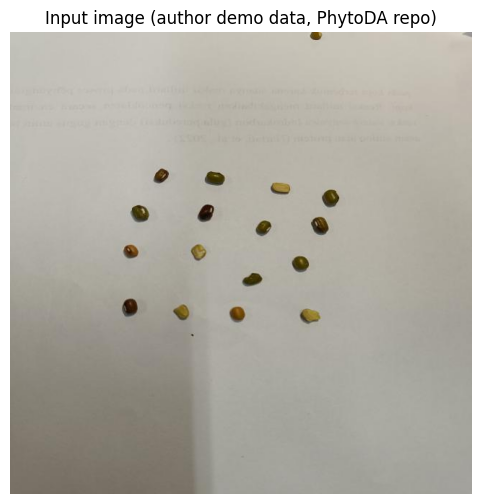

In [ ]:
import matplotlib.pyplot as plt

img_path = os.path.join(REPO_DIR, "dataset", "Seed", "seed_1.jpg")
raw_bgr = cv2.imread(img_path)
assert raw_bgr is not None, "demo image failed to load"
ih, iw = raw_bgr.shape[:2]
print(f"Input: dataset/Seed/seed_1.jpg | {iw}x{ih} px | {os.path.getsize(img_path)} bytes | commit {PINNED_COMMIT[:12]}")

plt.figure(figsize=(6, 6 * ih / iw))
plt.imshow(cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB))
plt.title("Input image (author demo data, PhytoDA repo)")
plt.axis("off")
plt.show()

## 5. Authors' unittest suite (depth-gated pipeline, mocked models)

Before spending GPU time we run the authors' own test file `tests/test_depth_gated_pipeline.py` at the pinned commit. It exercises `UniversalPhenoEngine._prepare_sam_input` (Otsu gating, hole filling, margins, weak-depth growth), strategy routing for all seven task strategies, and the mask contracts — with lightweight model doubles, so it needs no checkpoints and runs quickly on CPU.

**日本語**: 著者自身の unittest(モックモデル・合成画像)を実行し、depthゲート処理と 7 戦略のルーティングが固定コミットで正しく動くことを確認します。

In [ ]:
t0 = time.time()
r = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                   cwd=REPO_DIR, capture_output=True, text=True)
print(r.stdout[-3000:])
print(r.stderr[-3000:])
assert r.returncode == 0, f"author unittest suite FAILED (rc={r.returncode})"
print(f"Author unittest suite PASSED in {time.time()-t0:.1f} s")


xFormers not available
xFormers not available
test_all_seven_strategies_use_gated_rgb_and_preserve_measurement_input (test_depth_gated_pipeline.DepthGatedPipelineTests.test_all_seven_strategies_use_gated_rgb_and_preserve_measurement_input) ... ok
test_constant_depth_is_finite_and_empty_foreground_does_not_run_sam (test_depth_gated_pipeline.DepthGatedPipelineTests.test_constant_depth_is_finite_and_empty_foreground_does_not_run_sam) ... ok
test_gate_fills_only_small_enclosed_holes_and_preserves_anchor (test_depth_gated_pipeline.DepthGatedPipelineTests.test_gate_fills_only_small_enclosed_holes_and_preserves_anchor) ... ok
test_gate_margin_is_scaled_and_never_erases_foreground (test_depth_gated_pipeline.DepthGatedPipelineTests.test_gate_margin_is_scaled_and_never_erases_foreground) ... ok
test_leaf_diagnostics_account_for_filtered_and_duplicate_contours (test_depth_gated_pipeline.DepthGatedPipelineTests.test_leaf_diagnostics_account_for_filtered_and_duplicate_contours) ... ok
test_mask_co

## 6. Real inference: full depth-gated seed pipeline on the demo image

Now the actual pretrained run, using the author classes unchanged:
- `SeedPlugin` = `UniversalPhenoEngine(SeedStrategy())` (pinned `plugins/plugin_seed.py`);
- `engine.run(image, {"sam_type": "vit_b"})` executes: resize to ≤1024 px → DAv2 ViT-L depth (`infer_image(img, 518)`) → min-max normalize → Otsu foreground mask → gate refinement → SAM ViT-B automatic masks (`points_per_side=64`, `pred_iou_thresh=0.86`, `stability_score_thresh=0.92`, engine defaults from `SeedStrategy.get_config()`) → depth-overlap mask filtering → distance-transform watershed separation of touching seeds → geometry/color traits.

The only glue added for headless Colab (AI-authored, documented): Qt signals are connected to plain Python lists instead of GUI widgets. Device and progress reporting are the author code's own. Expect ~1–3 min on T4, several minutes on CPU.

**日本語**: 著者クラスをそのまま使い、デモ画像 1 枚で実推論を行います(depth推定 → Otsuゲート → SAM ViT-B → watershed で接触種子を分離 → 形状・色の計測)。GUI の代わりに Qt シグナルを Python リストに接続する以外は著者コードそのものです。

In [ ]:
sys.path.insert(0, REPO_DIR)
from plugins.plugin_seed import SeedPlugin  # author code, pinned commit

progress_log, results, errors = [], [], []
plugin = SeedPlugin()
plugin.update_progress.connect(lambda pct, msg: progress_log.append((pct, msg)))
plugin.result_ready.connect(lambda pack, stats, rows: results.append((pack, stats, rows)))
plugin.error_occurred.connect(errors.append)

t0 = time.time()
plugin.run(img_path, {"sam_type": "vit_b"})   # engine default SAM variant
elapsed = time.time() - t0

assert not errors, f"pipeline error: {errors}"
assert results, "pipeline produced no result"
image_pack, stats, analyzed = results[0]

print(f"Elapsed: {elapsed:.1f} s on {DEVICE}")
print("Diagnostics:", image_pack["diagnostics"])
print("Stats:", stats)
for pct, msg in progress_log:
    print(f"  [{pct:3d}%] {msg}")

--> [Hardware] Detected GPU: Tesla T4 (VRAM: 14.6 GB)


--> [Core] Loading SAM model (vit_b)...


--> [Core] AI Engines (vit_b) Started on cuda.


Elapsed: 32.7 s on cuda
Diagnostics: {'strategy': 'SeedStrategy', 'sam_type': 'vit_b', 'gate_pixels': 205102, 'gate_total_pixels': 409600, 'final_objects': 9, 'sam_candidates': 11}
Stats: {'Avg Area': 307, 'Avg Length': np.float64(20.5), 'Total Seeds': 9}
  [  5%] Loading image: /content/PhytoDA/dataset/Seed/seed_1.jpg...
  [ 10%] Engine: Loading AI Models (vit_b)...
  [ 20%] Engine: Estimating Depth...
  [ 30%] Strategy: Generating Prompts/Masks...
  [ 40%] Engine: Segmenting Depth-Gated RGB...
  [ 70%] Strategy: Task-Specific Segmentation & Analysis...
  [ 75%] Applying Watershed Segmentation...
  [ 85%] Analyzing Separated Seeds...
  [ 95%] Engine: Finalizing Six Views...
  [ 96%] Diagnostics: {'strategy': 'SeedStrategy', 'sam_type': 'vit_b', 'gate_pixels': 205102, 'gate_total_pixels': 409600, 'final_objects': 9, 'sam_candidates': 11}
  [100%] Analysis Complete.


## 7. The engine's six stage views

`UniversalPhenoEngine.run()` returns six views (pinned code, lines 179–209): original input, DAv2 depth as an Inferno colormap, the Otsu depth-gate mask, the gated RGB actually fed to SAM, all accepted SAM candidate masks, and the final cutout. These are the same panels the GUI shows.

**日本語**: エンジンが出力する 6 つのステージ画像(入力、depth、ゲートマスク、SAM入力、SAM候補、最終切り抜き)を表示します。

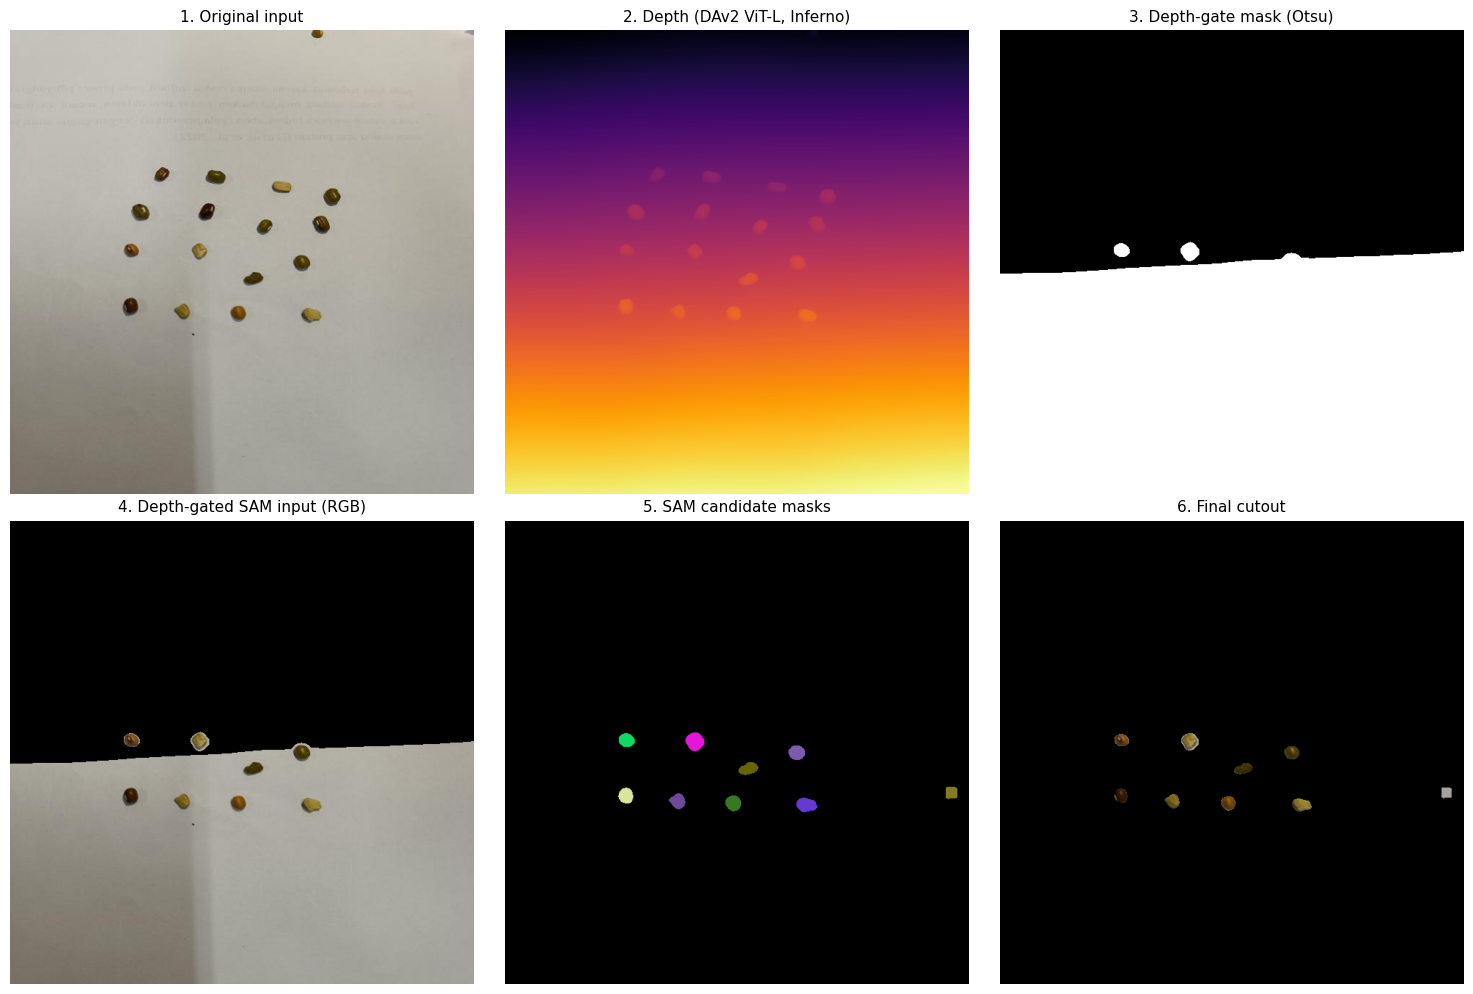

In [ ]:
titles = ["1. Original input", "2. Depth (DAv2 ViT-L, Inferno)",
          "3. Depth-gate mask (Otsu)", "4. Depth-gated SAM input (RGB)",
          "5. SAM candidate masks", "6. Final cutout"]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, im, t in zip(axes.ravel(), image_pack["steps"], titles):
    ax.imshow(im)
    ax.set_title(t, fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Annotated result

The main result view: the original image with the author's overlay — watershed-separated seed contours (green) and object IDs. This overlay is produced by `SeedStrategy.extract_features` from the actual model output, not by us.

**日本語**: 計測結果の注釈付き画像(緑輪郭 = 分離された種子、数字 = オブジェクト ID)を表示します。

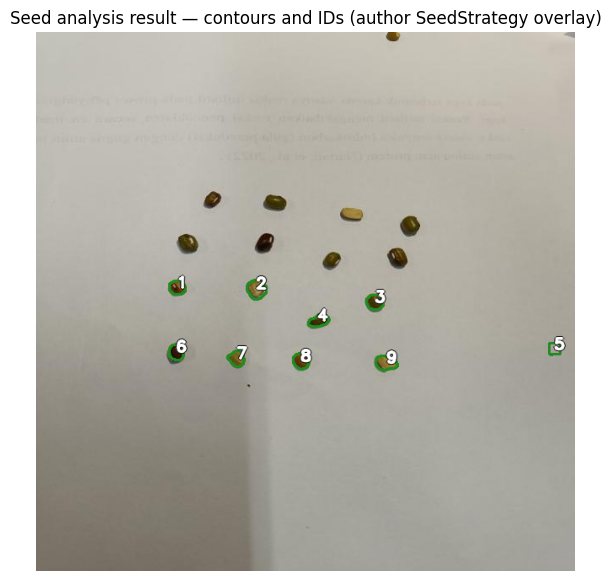

In [ ]:
mh, mw = image_pack["main"].shape[:2]
plt.figure(figsize=(7, 7 * mh / mw))
plt.imshow(image_pack["main"])
plt.title("Seed analysis result — contours and IDs (author SeedStrategy overlay)")
plt.axis("off")
plt.show()

## 9. Measurement table and CSV export

The per-seed measurements computed by the author's trait code. Lengths/widths/perimeters/areas are in **pixels of the original image** (this code path has no physical calibration); color is the mean RGB of each seed mapped to the author's `ColorNamer` palette. We export the table as CSV for further use.

**日本語**: 種子ごとの計測結果(長さ・幅・L/W 比・円形度・面積はピクセル単位、色は著者の ColorNamer による)を表と CSV で出力します。

In [ ]:
import pandas as pd

df = pd.DataFrame([{k: v for k, v in row.items() if not k.startswith("_")} for row in analyzed])
print(df.to_string(index=False))
csv_path = "/content/seed_1_measurements.csv"
df.to_csv(csv_path, index=False)
print(f"\nSaved {len(df)} seed rows to {csv_path}")

 Area  Circularity     Color ColorHex  ID  L/W Ratio  Length  Perimeter           RGB Swatch  Width
  277         0.98     Sepia  #644423   1       1.19    19.0       59.5   100, 68, 35          16.0
  434         0.97   DimGray  #8A7B4E   2       1.03    22.6       75.0  138, 123, 78          21.9
  310         1.00     Sepia  #473D10   3       1.18    20.0       62.3    71, 61, 16          17.0
  282         0.80     Black  #3B330E   4       1.84    25.6       66.5    59, 51, 14          13.9
  196         0.90  DarkGray  #A5A09A   5       1.08    14.0       52.2 165, 160, 154          13.0
  294         0.93     Black  #331E0E   6       1.06    19.0       62.9    51, 30, 14          18.0
  290         0.92     Sepia  #6D5B23   7       1.07    18.9       62.8   109, 91, 35          17.6
  314         0.95     Sepia  #674716   8       1.00    19.0       64.3   103, 71, 22          19.0
  369         0.87 OliveDrab  #816F31   9       1.53    26.0       73.1  129, 111, 49          17.0


## 10. Interpretation and limitations

- **What was verified here:** the authors' pinned code passes their own depth-gated-pipeline unittest suite, and the real pretrained engine (DAv2 ViT-L + SAM ViT-B) runs end-to-end headlessly on an author demo image, producing the documented six stage views and a seed measurement table.
- **What was NOT verified:** dataset-level accuracy claims of the paper (e.g., seed MAPE 3.87% vs expert references, the OpenPheno comparison, the CVPPP depth-gating ablation) — those require the paper's evaluation sets and expert references and are out of scope for a single-image demo. The GUI, manual annotation, and Copilot layers are also not exercised.
- Units are pixels; no mm calibration is applied by this code path. Mask quality depends on the demo image and SAM's automatic-mask parameters chosen by the authors for this task.

**References:** paper DOI 10.1016/j.cropd.2026.100168 · code https://github.com/Jeepu/PhytoDA (commit 5137be9, MIT) · SAM: Kirillov et al., ICCV 2023 · Depth Anything V2: Yang et al., 2024 · demo image: authors' `dataset/Seed/seed_1.jpg`.

**日本語**: 本ノートブックで検証できたのは、著者 unittest の成功とデモ画像 1 枚での実推論(6 ステージ画像・計測表の生成)までです。論文のデータセット規模の精度主張(MAPE 等)や GUI/Copilot 機能は検証対象外です。単位はピクセルで、物理校正はこのコード経路には含まれません。